# BharatMarket AI
## Notebook 02: Exploratory Data Analysis

### Objective
To perform exploratory data analysis on ten Indian market instruments
using five years of historical daily OHLCV data.

### Analysis Performed
1. Historical price analysis
2. Daily and monthly returns
3. Annual performance
4. Volatility analysis
5. Correlation analysis
6. Maximum drawdown
7. Trading volume analysis
8. Risk-return comparison

### Instruments
NIFTY 50, BANK NIFTY and eight NSE-listed companies.

In [1]:
# ============================================
# CELL 1: IMPORT LIBRARIES
# ============================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from IPython.display import display

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.titlesize"] = 15

print("BharatMarket AI - EDA Started")
print("All libraries imported successfully!")

BharatMarket AI - EDA Started
All libraries imported successfully!


In [2]:
# ============================================
# CELL 2: LOAD PROCESSED DATA
# ============================================

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"

OUTPUT_DIR = PROJECT_DIR / "outputs"

CHART_DIR = OUTPUT_DIR / "charts"
REPORT_DIR = OUTPUT_DIR / "reports"

CHART_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

INSTRUMENTS = {
    "NIFTY50": "NIFTY 50",
    "BANKNIFTY": "BANK NIFTY",
    "RELIANCE": "Reliance Industries",
    "TCS": "Tata Consultancy Services",
    "HDFCBANK": "HDFC Bank",
    "INFY": "Infosys",
    "ICICIBANK": "ICICI Bank",
    "SBIN": "State Bank of India",
    "ITC": "ITC Limited",
    "LT": "Larsen & Toubro"
}

market_data = {}

for symbol, company in INSTRUMENTS.items():

    file_path = PROCESSED_DATA_DIR / f"{symbol}_processed.csv"

    if not file_path.exists():
        print("Missing:", file_path)
        continue

    df = pd.read_csv(file_path)

    df["date"] = pd.to_datetime(df["date"])

    df = df.sort_values("date").reset_index(drop=True)

    market_data[symbol] = df

    print(f"{symbol}: {len(df)} records loaded")

print("\nTotal instruments loaded:", len(market_data))

assert len(market_data) == 10, "Please check missing processed datasets."

NIFTY50: 1236 records loaded
BANKNIFTY: 1235 records loaded
RELIANCE: 1237 records loaded
TCS: 1237 records loaded
HDFCBANK: 1237 records loaded
INFY: 1237 records loaded
ICICIBANK: 1237 records loaded
SBIN: 1237 records loaded
ITC: 1237 records loaded
LT: 1237 records loaded

Total instruments loaded: 10


In [3]:
# ============================================
# CELL 3: DESCRIPTIVE STATISTICS
# ============================================

summary_results = []

for symbol, df in market_data.items():

    summary_results.append({

        "Symbol": symbol,

        "Observations": len(df),

        "Mean Close": df["close"].mean(),

        "Median Close": df["close"].median(),

        "Maximum Close": df["close"].max(),

        "Minimum Close": df["close"].min(),

        "Mean Volume": df["volume"].mean(),

        "Price Std Dev": df["close"].std()

    })

summary_df = pd.DataFrame(summary_results)

display(
    summary_df.round(2)
)

summary_df.to_csv(
    REPORT_DIR / "descriptive_statistics.csv",
    index=False
)

,Symbol,Observations,Mean Close,Median Close,Maximum Close,Minimum Close,Mean Volume,Price Std Dev
0,NIFTY50,1236,21514.62,22491.10,26328.55,15293.50,308408.33,3235.58
1,BANKNIFTY,1235,48115.13,48493.05,64635.20,32617.10,1774695.47,7651.33
2,RELIANCE,1237,1290.05,1274.50,1600.90,1015.88,13458331.68,139.72
3,TCS,1237,3368.55,3384.20,4553.75,1982.60,2676630.03,571.37
4,HDFCBANK,1237,815.33,805.58,1012.90,640.65,28677149.09,91.70
5,INFY,1237,1519.26,1509.00,1999.70,985.30,7934457.23,227.56
6,ICICIBANK,1237,1113.91,1123.80,1640.00,653.75,14017098.54,246.09
7,SBIN,1237,737.95,759.05,1227.80,434.70,14695912.17,195.31
8,ITC,1237,364.96,400.75,503.36,200.77,16284157.41,78.06
9,LT,1237,3062.72,3457.65,4418.10,1471.80,2161531.93,838.37


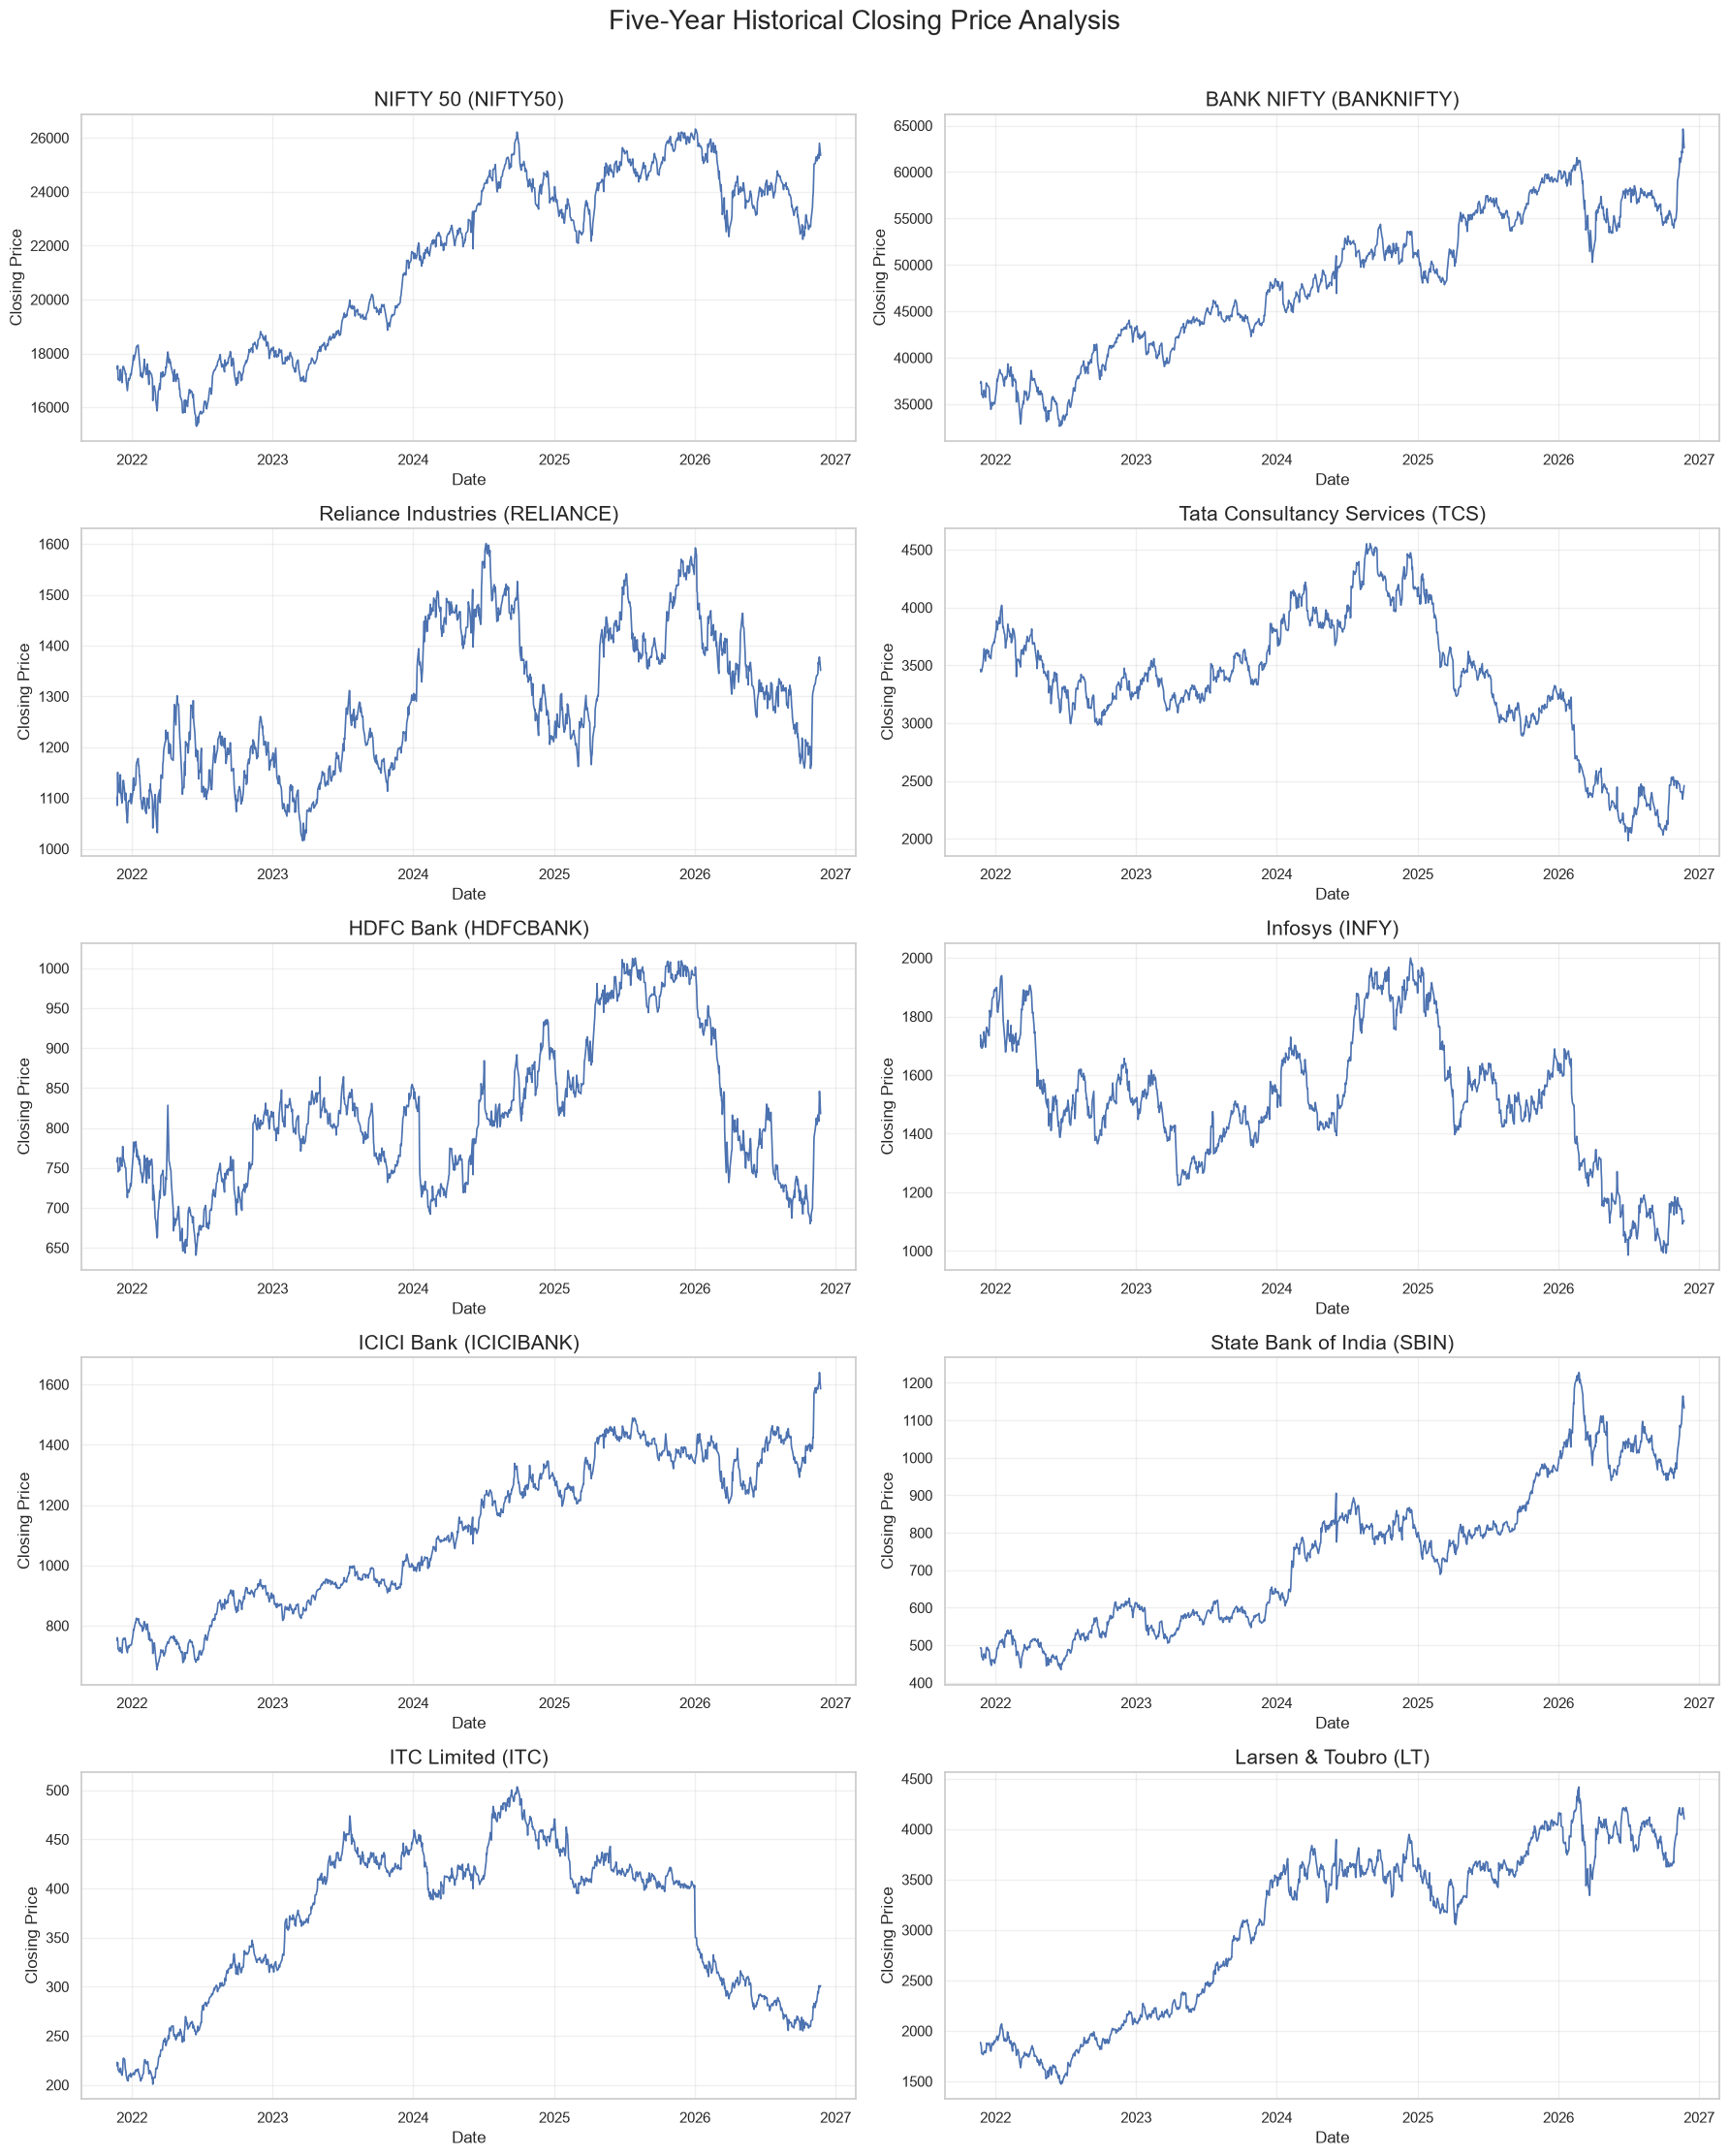

In [4]:
# ============================================
# CELL 4: HISTORICAL PRICE ANALYSIS
# ============================================

fig, axes = plt.subplots(
    5, 2,
    figsize=(18, 22)
)

axes = axes.flatten()

for i, (symbol, df) in enumerate(market_data.items()):

    axes[i].plot(
        df["date"],
        df["close"],
        linewidth=1.2
    )

    axes[i].set_title(
        f"{INSTRUMENTS[symbol]} ({symbol})"
    )

    axes[i].set_xlabel("Date")
    axes[i].set_ylabel("Closing Price")

    axes[i].grid(alpha=0.3)

plt.suptitle(
    "Five-Year Historical Closing Price Analysis",
    fontsize=20,
    y=1.01
)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "all_instruments_historical_prices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

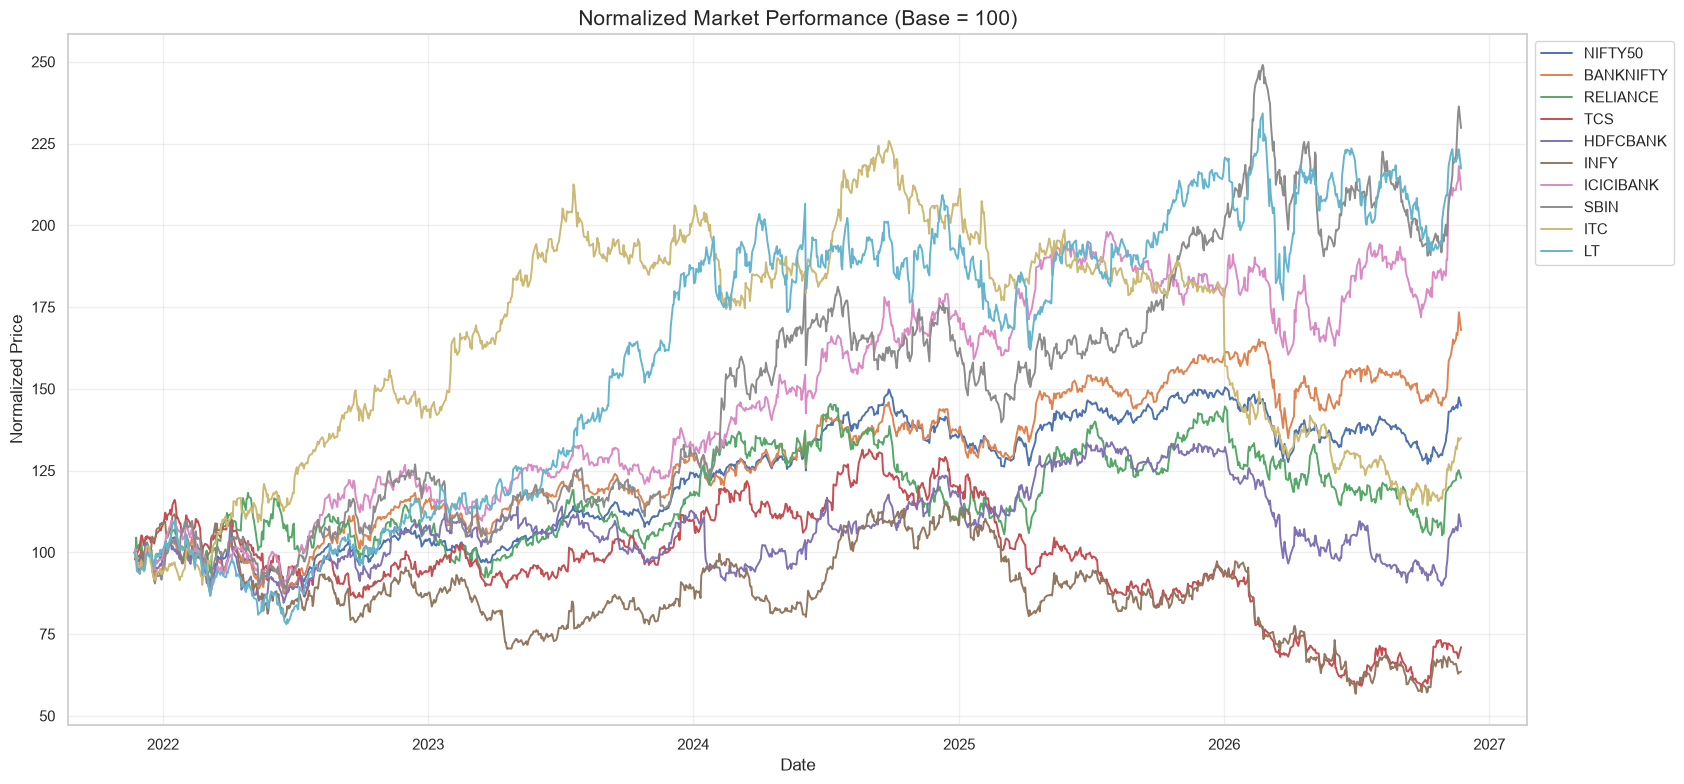

In [5]:
# ============================================
# CELL 5: NORMALIZED PRICE COMPARISON
# ============================================

normalized_prices = pd.DataFrame()

for symbol, df in market_data.items():

    temp = df[["date", "close"]].copy()

    first_valid_price = temp["close"].dropna().iloc[0]

    temp["normalized_price"] = (
        temp["close"] / first_valid_price
    ) * 100

    temp = temp.set_index("date")

    normalized_prices[symbol] = temp["normalized_price"]

plt.figure(figsize=(17, 8))

for symbol in normalized_prices.columns:

    plt.plot(
        normalized_prices.index,
        normalized_prices[symbol],
        label=symbol,
        linewidth=1.4
    )

plt.title("Normalized Market Performance (Base = 100)")

plt.xlabel("Date")
plt.ylabel("Normalized Price")

plt.legend(
    loc="upper left",
    bbox_to_anchor=(1, 1)
)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "normalized_market_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [6]:
# ============================================
# CELL 6: DAILY RETURNS
# ============================================

daily_returns = pd.DataFrame()

for symbol, df in market_data.items():

    price_column = (
        "adj_close"
        if "adj_close" in df.columns
        else "close"
    )

    temp = df[["date", price_column]].copy()

    temp[price_column] = pd.to_numeric(
        temp[price_column],
        errors="coerce"
    )

    temp["daily_return"] = (
        temp[price_column].pct_change(fill_method=None) * 100
    )

    temp = temp.set_index("date")

    daily_returns[symbol] = temp["daily_return"]

display(daily_returns.head(10))

,NIFTY50,BANKNIFTY,RELIANCE,TCS,HDFCBANK,INFY,ICICIBANK,SBIN,ITC,LT
date,,,,,,,,,,
2021-11-23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-11-24,-0.504468,0.453817,-1.443908,-0.604739,0.164955,-2.354755,1.110598,0.020286,-1.683935,-1.264343
2021-11-25,0.695945,-0.206186,6.019824,0.075517,0.520406,1.556613,-1.203635,-0.527226,1.581014,-0.676513
2021-11-26,-2.907125,-3.584260,-3.223101,0.027562,-2.362469,-1.785316,-3.841288,-4.087253,-3.156062,-3.878577
2021-11-29,0.161513,-0.136157,1.197880,1.600004,0.761799,0.277835,-0.526172,-1.147708,-1.116063,-0.613012
2021-11-30,-0.414860,-0.781477,-1.478589,0.775268,-0.512909,0.960889,-0.563764,-0.978286,-0.158024,-0.141454
2021-12-01,1.081664,1.875870,2.560897,1.378544,0.743194,0.131381,1.868840,3.202686,0.339138,1.204131
2021-12-02,1.367457,0.394197,0.642477,1.819551,1.402313,1.944718,-0.728308,0.357679,1.599833,0.179170
2021-12-03,-1.177769,-0.852140,-3.004616,-0.067246,-0.799591,-0.726446,-0.844420,-0.807138,-1.685534,0.673489


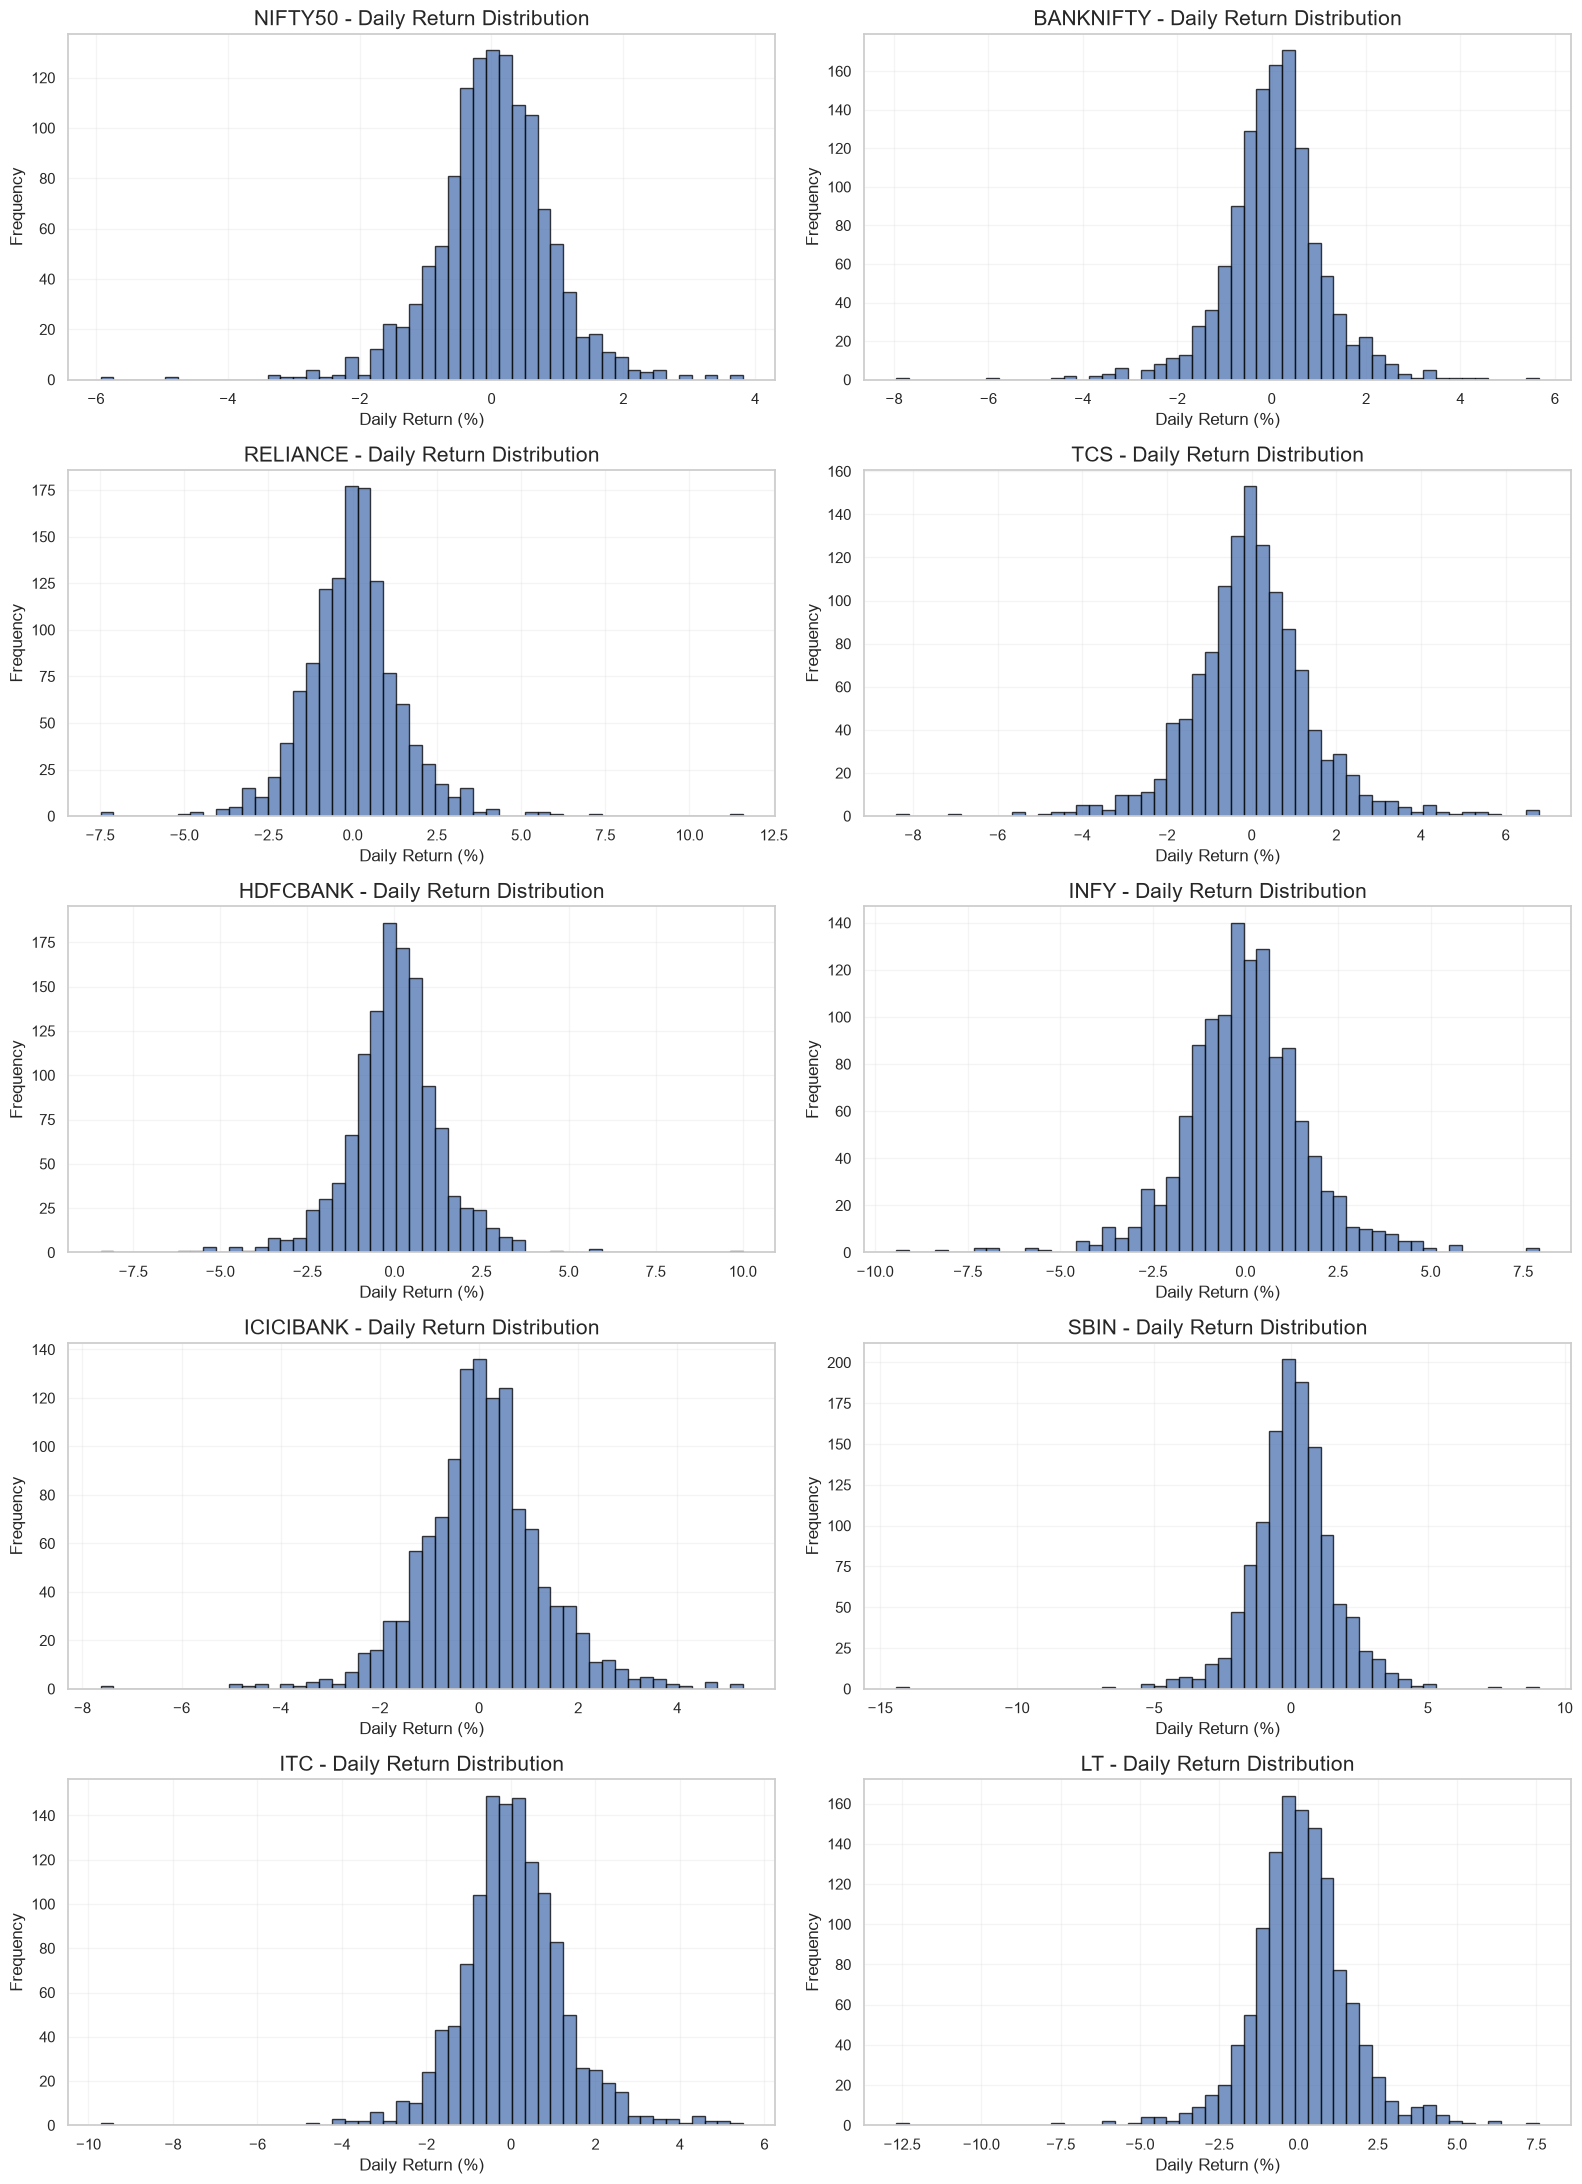

In [7]:
# ============================================
# CELL 7: DAILY RETURN DISTRIBUTION
# ============================================

fig, axes = plt.subplots(
    5, 2,
    figsize=(16, 22)
)

axes = axes.flatten()

for i, symbol in enumerate(daily_returns.columns):

    returns = daily_returns[symbol].dropna()

    axes[i].hist(
        returns,
        bins=50,
        edgecolor="black",
        alpha=0.75
    )

    axes[i].set_title(
        f"{symbol} - Daily Return Distribution"
    )

    axes[i].set_xlabel("Daily Return (%)")
    axes[i].set_ylabel("Frequency")

    axes[i].grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "daily_return_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
# ============================================
# CELL 8: MONTHLY RETURNS
# ============================================

monthly_returns = (
    daily_returns
    .resample("ME")
    .apply(lambda x: (1 + x.dropna() / 100).prod() - 1)
    * 100
)

display(monthly_returns.tail(12).round(2))

monthly_returns.to_csv(
    REPORT_DIR / "monthly_returns.csv"
)

,NIFTY50,BANKNIFTY,RELIANCE,TCS,HDFCBANK,INFY,ICICIBANK,SBIN,ITC,LT
date,,,,,,,,,,
2025-12-31,-0.28,-0.29,0.19,2.19,-1.63,3.54,-3.31,0.33,-0.31,0.34
2026-01-31,-3.10,0.05,-11.14,-0.80,-6.25,1.58,0.90,9.67,-20.06,-3.70
2026-02-28,-0.56,1.54,-0.11,-15.57,-4.47,-20.77,1.76,11.56,-0.61,8.80
2026-03-31,-11.31,-16.94,-3.59,-10.56,-17.60,-3.81,-12.55,-18.50,-8.26,-18.10
2026-04-30,7.46,9.13,6.47,4.88,5.49,-5.50,4.77,9.09,9.45,14.55
2026-05-31,-1.87,-1.14,-7.66,-7.45,-3.52,-1.77,-0.55,-8.11,-6.41,2.55
2026-06-30,1.35,6.09,-1.61,-10.07,8.94,-11.96,9.46,6.48,0.02,1.64
2026-07-31,2.17,-0.48,1.07,17.08,-6.24,12.96,4.38,0.05,-2.07,-4.94
2026-08-31,-1.24,1.33,-2.36,1.42,-5.23,0.33,2.15,3.17,-9.07,2.69


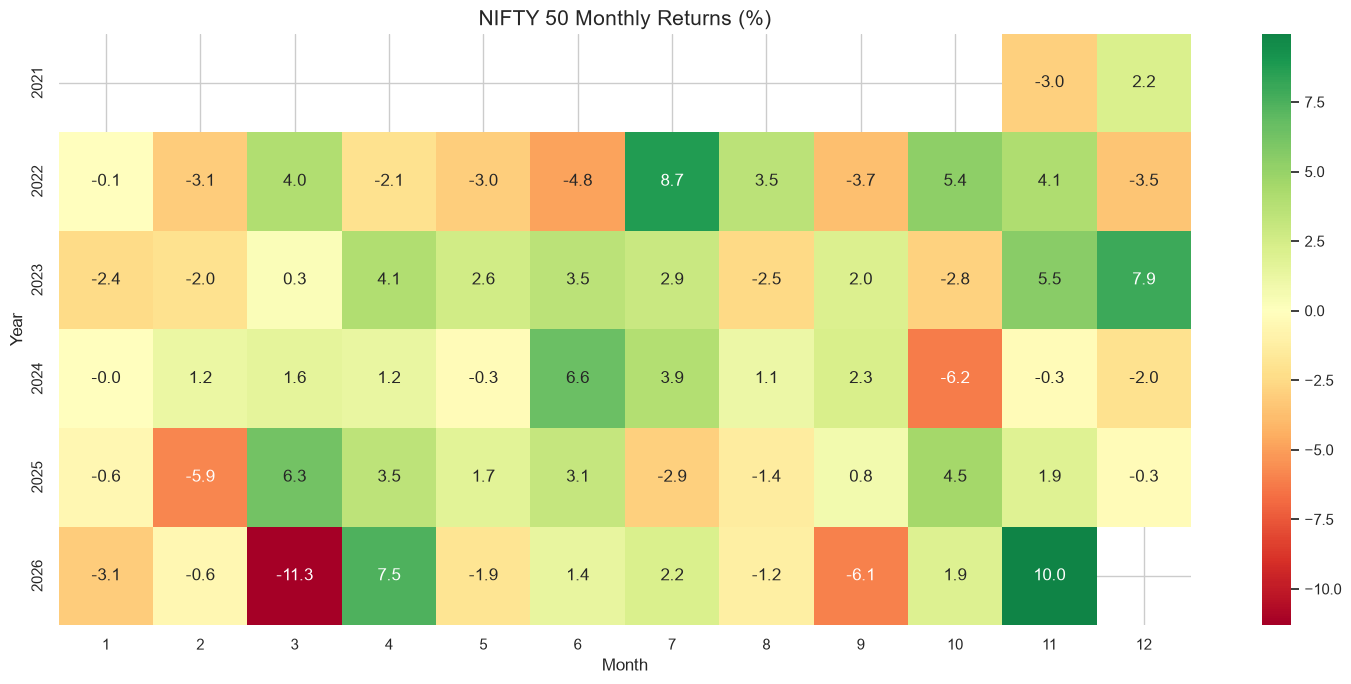

In [9]:
# ============================================
# CELL 9: NIFTY MONTHLY RETURN HEATMAP
# ============================================

nifty_monthly = monthly_returns["NIFTY50"].dropna()

nifty_monthly_df = nifty_monthly.to_frame(
    name="return"
)

nifty_monthly_df["year"] = nifty_monthly_df.index.year
nifty_monthly_df["month"] = nifty_monthly_df.index.month

heatmap_data = nifty_monthly_df.pivot(
    index="year",
    columns="month",
    values="return"
)

plt.figure(figsize=(15, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    center=0
)

plt.title("NIFTY 50 Monthly Returns (%)")

plt.xlabel("Month")
plt.ylabel("Year")

plt.tight_layout()

plt.savefig(
    CHART_DIR / "nifty50_monthly_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
# ============================================
# CELL 10: ANNUAL RETURNS
# ============================================

annual_returns = (
    daily_returns
    .resample("YE")
    .apply(lambda x: (1 + x.dropna() / 100).prod() - 1)
    * 100
)

annual_returns.index = annual_returns.index.year

display(annual_returns.round(2))

annual_returns.to_csv(
    REPORT_DIR / "annual_returns.csv"
)

,NIFTY50,BANKNIFTY,RELIANCE,TCS,HDFCBANK,INFY,ICICIBANK,SBIN,ITC,LT
date,,,,,,,,,,
2021,-0.85,-4.81,-0.74,7.91,-2.39,8.69,-1.56,-6.61,-5.85,0.51
2022,4.33,21.15,7.91,-11.68,11.33,-18.38,21.08,35.36,59.50,11.43
2023,20.03,12.34,10.34,20.64,6.19,5.02,12.79,6.65,44.84,70.97
2024,8.80,5.32,-5.64,10.01,5.14,25.70,29.71,25.89,8.22,3.12
2025,10.51,17.15,29.72,-18.98,13.33,-11.53,5.59,26.04,-10.48,14.25
2026,-2.98,5.04,-13.57,-19.96,-16.13,-28.62,19.06,17.40,-21.67,1.38


In [11]:
# ============================================
# CELL 11: ANNUALIZED VOLATILITY
# ============================================

volatility_results = []

for symbol in daily_returns.columns:

    returns = daily_returns[symbol].dropna()

    daily_volatility = returns.std()

    annualized_volatility = (
        daily_volatility * np.sqrt(252)
    )

    volatility_results.append({

        "Symbol": symbol,

        "Daily Volatility (%)": daily_volatility,

        "Annualized Volatility (%)": annualized_volatility

    })

volatility_df = pd.DataFrame(volatility_results)

volatility_df = volatility_df.sort_values(
    "Annualized Volatility (%)",
    ascending=False
)

display(volatility_df.round(2))

volatility_df.to_csv(
    REPORT_DIR / "volatility_analysis.csv",
    index=False
)

,Symbol,Daily Volatility (%),Annualized Volatility (%)
5,INFY,1.66,26.37
7,SBIN,1.54,24.44
9,LT,1.54,24.42
3,TCS,1.45,22.98
2,RELIANCE,1.44,22.81
4,HDFCBANK,1.34,21.32
6,ICICIBANK,1.25,19.88
8,ITC,1.25,19.79
1,BANKNIFTY,1.07,17.05
0,NIFTY50,0.88,13.94


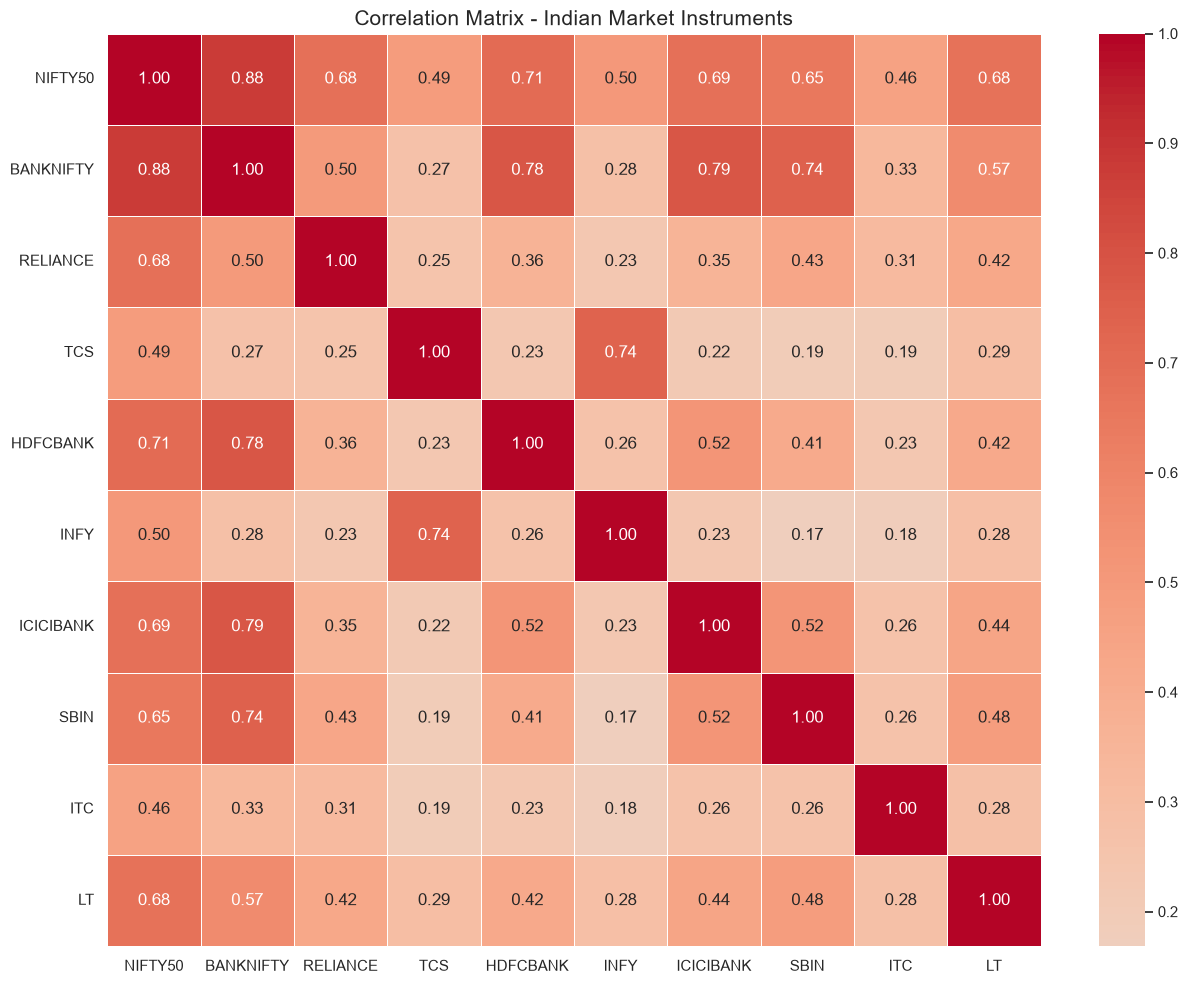

In [12]:
# ============================================
# CELL 12: CORRELATION ANALYSIS
# ============================================

correlation_matrix = daily_returns.corr(
    min_periods=30
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix - Indian Market Instruments")

plt.tight_layout()

plt.savefig(
    CHART_DIR / "market_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

correlation_matrix.to_csv(
    REPORT_DIR / "correlation_matrix.csv"
)

In [13]:
# ============================================
# CELL 13: MAXIMUM DRAWDOWN
# ============================================

drawdown_results = []

for symbol, df in market_data.items():

    price_column = (
        "adj_close"
        if "adj_close" in df.columns
        else "close"
    )

    prices = pd.to_numeric(
        df[price_column],
        errors="coerce"
    ).dropna()

    running_peak = prices.cummax()

    drawdown = (
        (prices / running_peak) - 1
    ) * 100

    drawdown_results.append({

        "Symbol": symbol,

        "Maximum Drawdown (%)": drawdown.min(),

        "Average Drawdown (%)": drawdown.mean()

    })

drawdown_df = pd.DataFrame(drawdown_results)

drawdown_df = drawdown_df.sort_values(
    "Maximum Drawdown (%)"
)

display(drawdown_df.round(2))

drawdown_df.to_csv(
    REPORT_DIR / "maximum_drawdown.csv",
    index=False
)

,Symbol,Maximum Drawdown (%),Average Drawdown (%)
3,TCS,-53.39,-18.72
5,INFY,-48.17,-20.63
8,ITC,-45.04,-13.10
4,HDFCBANK,-31.74,-9.44
9,LT,-28.88,-7.40
2,RELIANCE,-27.18,-10.62
7,SBIN,-23.94,-8.18
6,ICICIBANK,-20.73,-5.16
1,BANKNIFTY,-18.32,-4.63
0,NIFTY50,-16.47,-5.14


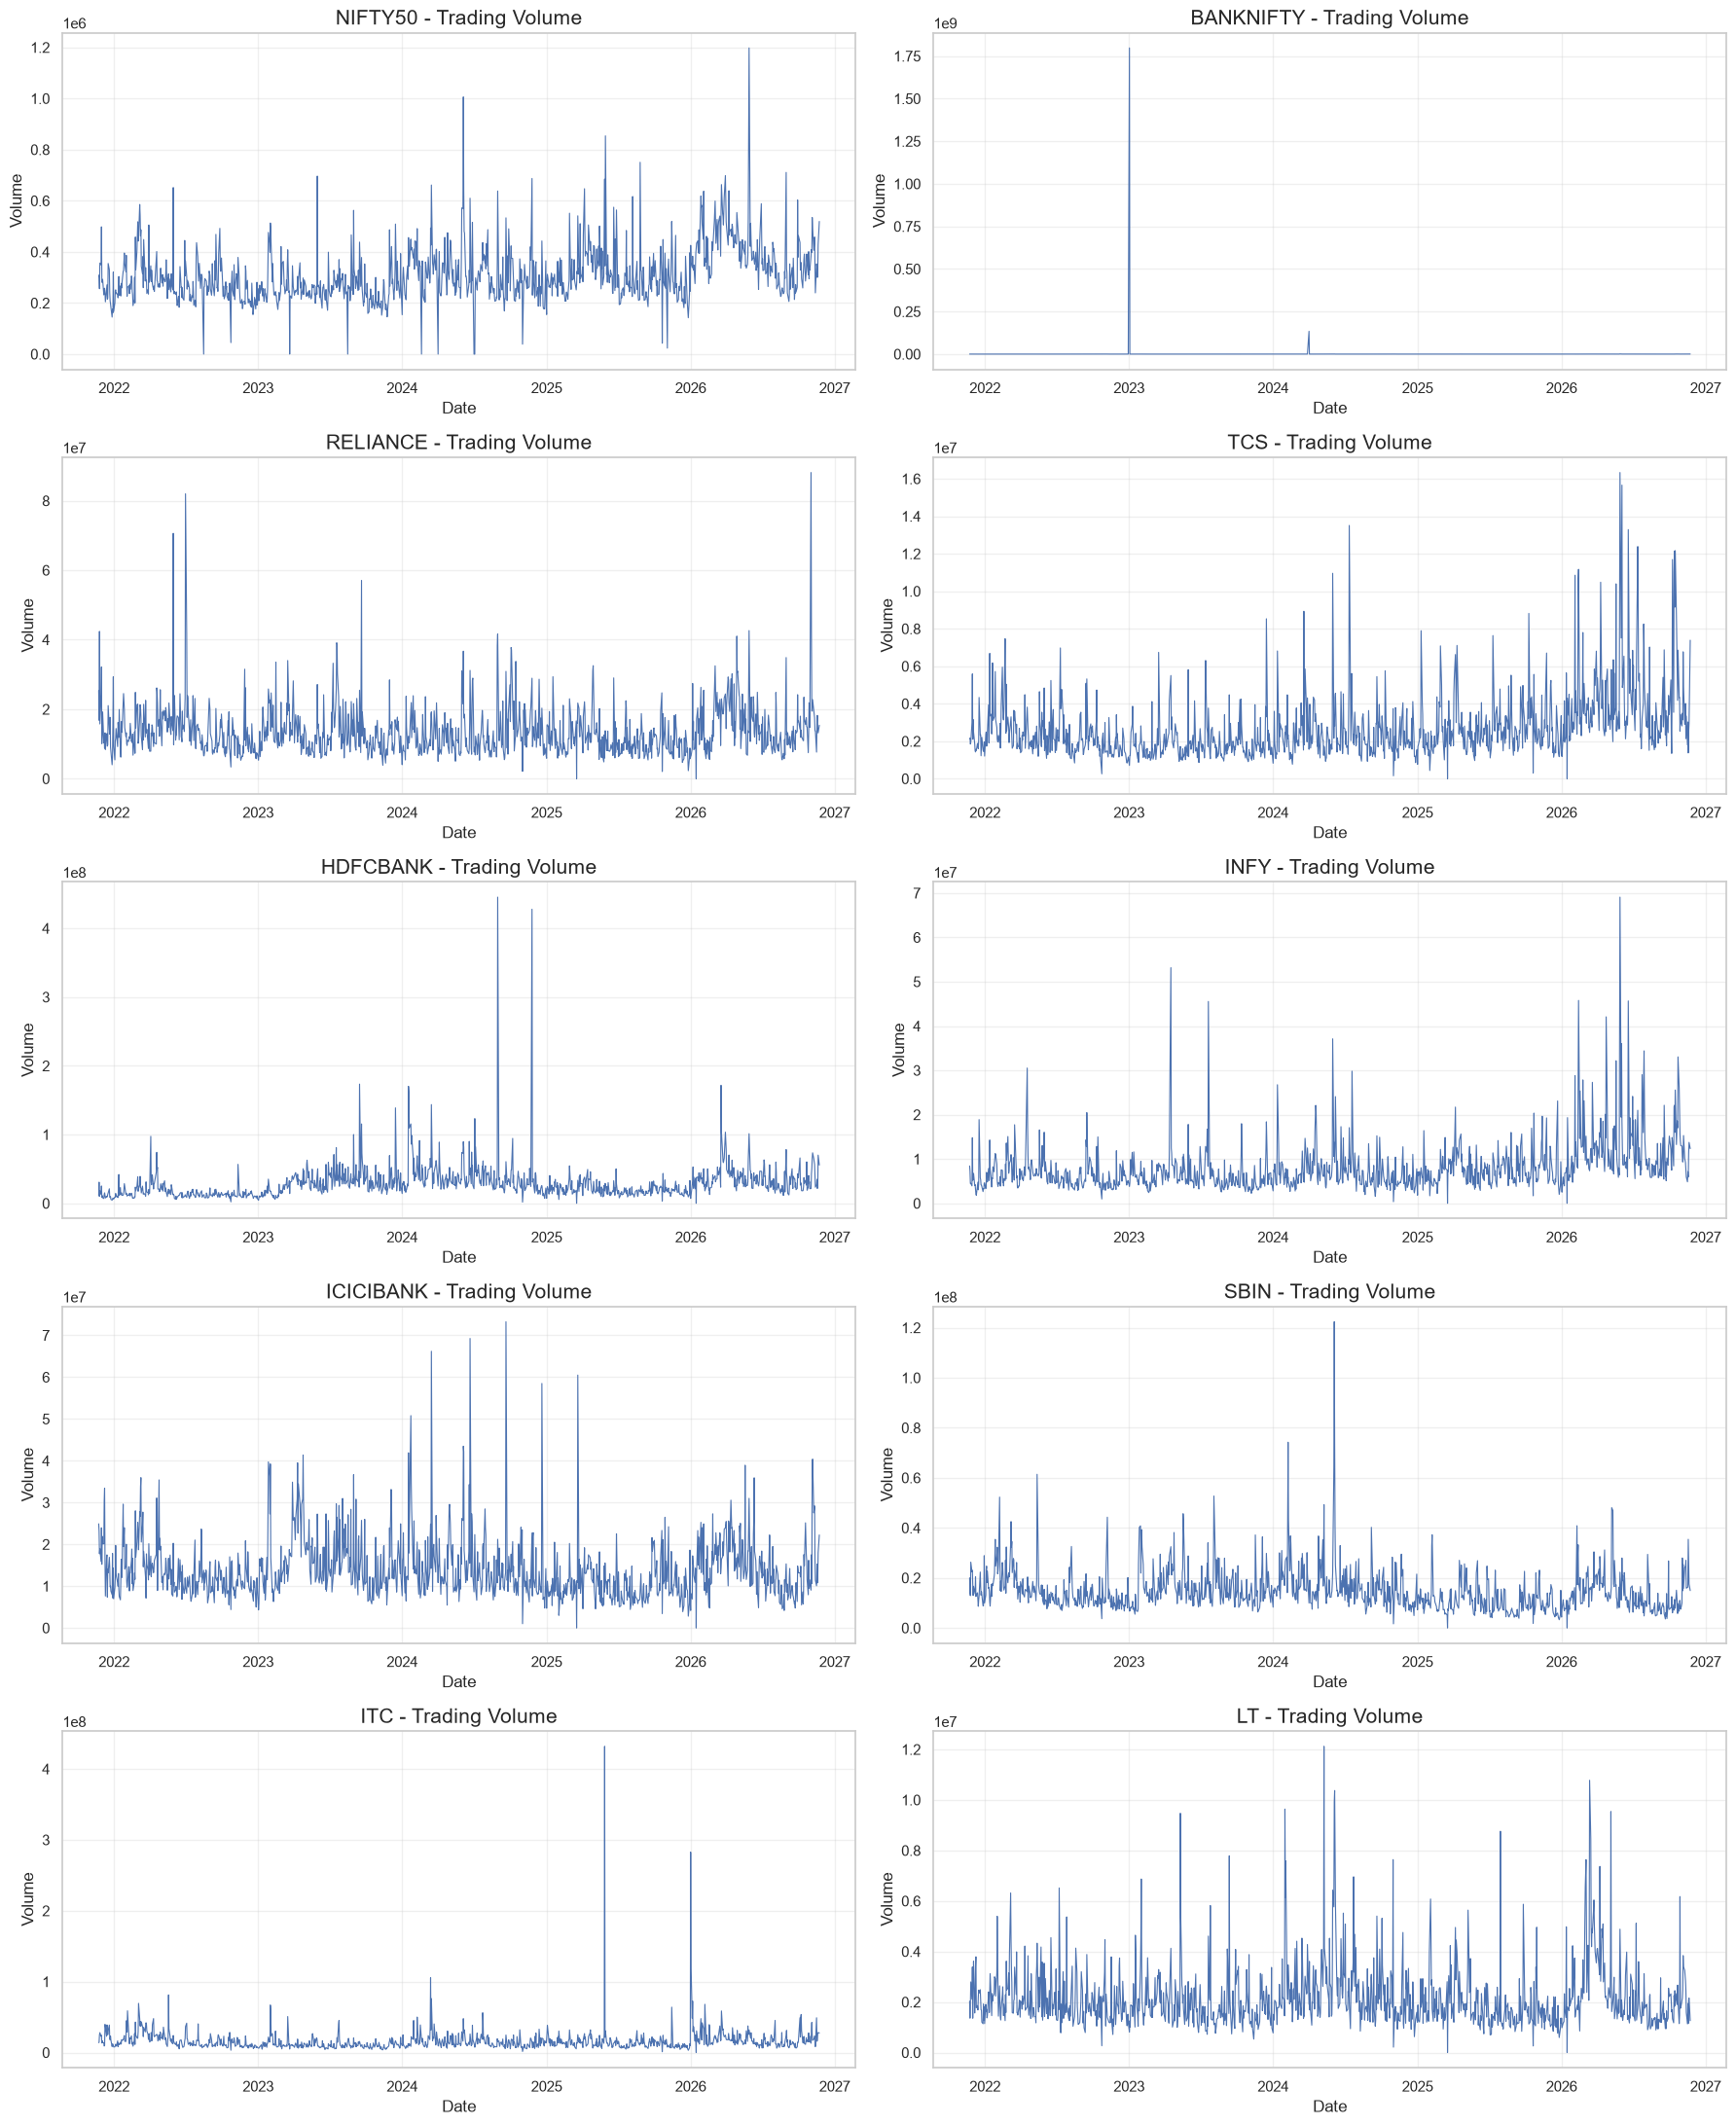

In [14]:
# ============================================
# CELL 14: TRADING VOLUME ANALYSIS
# ============================================

fig, axes = plt.subplots(
    5, 2,
    figsize=(18, 22)
)

axes = axes.flatten()

for i, (symbol, df) in enumerate(market_data.items()):

    axes[i].plot(
        df["date"],
        df["volume"],
        linewidth=0.8
    )

    axes[i].set_title(
        f"{symbol} - Trading Volume"
    )

    axes[i].set_xlabel("Date")
    axes[i].set_ylabel("Volume")

    axes[i].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "volume_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

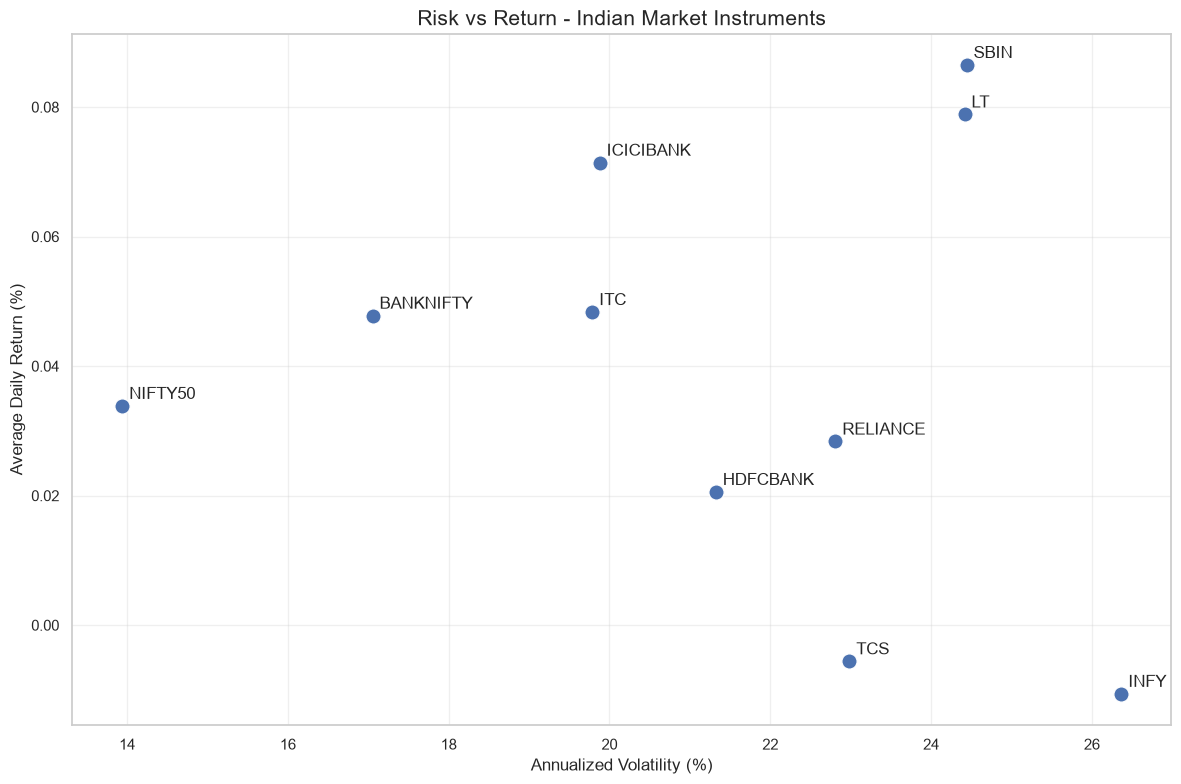

,Average Daily Return (%),Annualized Volatility (%)
NIFTY50,0.034,13.941
BANKNIFTY,0.048,17.054
RELIANCE,0.028,22.810
TCS,-0.006,22.983
HDFCBANK,0.021,21.323
INFY,-0.011,26.367
ICICIBANK,0.071,19.878
SBIN,0.087,24.442
ITC,0.048,19.786
LT,0.079,24.417


In [15]:
# ============================================
# CELL 15: RISK-RETURN ANALYSIS
# ============================================

risk_return = pd.DataFrame({
    "Average Daily Return (%)": daily_returns.mean(),
    "Annualized Volatility (%)": daily_returns.std() * np.sqrt(252)
})

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=risk_return,
    x="Annualized Volatility (%)",
    y="Average Daily Return (%)",
    s=120
)

for symbol, row in risk_return.iterrows():

    plt.annotate(
        symbol,
        (
            row["Annualized Volatility (%)"],
            row["Average Daily Return (%)"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Risk vs Return - Indian Market Instruments")

plt.xlabel("Annualized Volatility (%)")
plt.ylabel("Average Daily Return (%)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "risk_return_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(risk_return.round(3))

risk_return.to_csv(
    REPORT_DIR / "risk_return_analysis.csv"
)

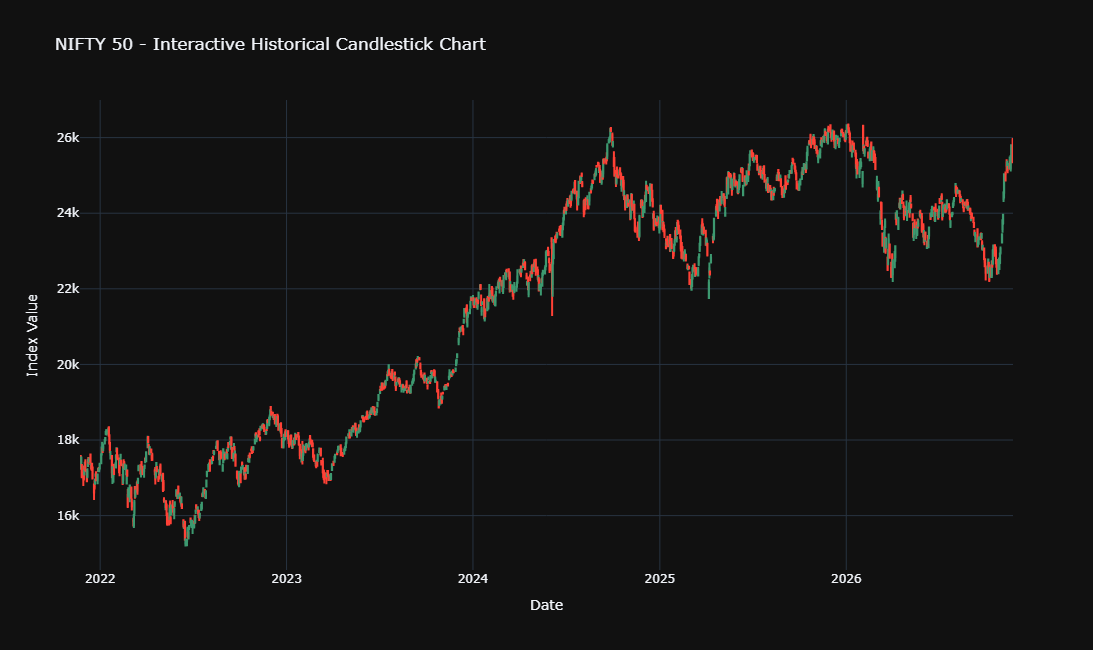

In [16]:
# ============================================
# CELL 16: INTERACTIVE NIFTY CHART
# ============================================

nifty = market_data["NIFTY50"]

fig = go.Figure()

fig.add_trace(
    go.Candlestick(

        x=nifty["date"],

        open=nifty["open"],

        high=nifty["high"],

        low=nifty["low"],

        close=nifty["close"],

        name="NIFTY 50"

    )
)

fig.update_layout(

    title="NIFTY 50 - Interactive Historical Candlestick Chart",

    xaxis_title="Date",

    yaxis_title="Index Value",

    template="plotly_dark",

    xaxis_rangeslider_visible=False,

    height=650

)

fig.show()

fig.write_html(
    str(CHART_DIR / "nifty50_interactive_chart.html")
)

In [17]:
# ============================================
# CELL 17: COMBINED EDA SUMMARY
# ============================================

eda_summary = pd.DataFrame(index=daily_returns.columns)

eda_summary["Average Daily Return (%)"] = (
    daily_returns.mean()
)

eda_summary["Annualized Return (%)"] = (
    daily_returns.mean() * 252
)

eda_summary["Annualized Volatility (%)"] = (
    daily_returns.std() * np.sqrt(252)
)

eda_summary["Best Daily Return (%)"] = (
    daily_returns.max()
)

eda_summary["Worst Daily Return (%)"] = (
    daily_returns.min()
)

eda_summary["Positive Days"] = (
    daily_returns.gt(0).sum()
)

eda_summary["Negative Days"] = (
    daily_returns.lt(0).sum()
)

eda_summary = eda_summary.round(3)

display(eda_summary)

eda_summary.to_csv(
    REPORT_DIR / "complete_eda_summary.csv"
)

print("EDA analysis completed successfully!")

,Average Daily Return (%),Annualized Return (%),Annualized Volatility (%),Best Daily Return (%),Worst Daily Return (%),Positive Days,Negative Days
NIFTY50,0.034,8.531,13.941,3.818,-5.929,649,585
BANKNIFTY,0.048,12.044,17.054,5.667,-7.947,656,578
RELIANCE,0.028,7.145,22.810,11.598,-7.485,628,604
TCS,-0.006,-1.406,22.983,6.791,-8.386,593,641
HDFCBANK,0.021,5.184,21.323,10.013,-8.436,626,606
INFY,-0.011,-2.673,26.367,7.934,-9.423,608,625
ICICIBANK,0.071,17.996,19.878,5.330,-7.634,642,591
SBIN,0.087,21.798,24.442,9.068,-14.404,661,566
ITC,0.048,12.185,19.786,5.498,-9.715,620,610
LT,0.079,19.874,24.417,7.590,-12.675,635,599


EDA analysis completed successfully!
